# 01 — EDA
Exploración del dataset. **No forma parte de la entrega.**

In [1]:
import pandas as pd

train = pd.read_json("../data/train_data.jsonlines", lines=True)
test = pd.read_json("../data/test_data.jsonlines", lines=True)

print(train.shape, test.shape)   # esperado: (70000, 45) (30000, 44)

(70000, 45) (30000, 44)


In [2]:
train["condition"].value_counts(normalize=True)

condition
new     0.536971
used    0.463029
Name: proportion, dtype: float64

In [3]:
train.head()

,seller_address,warranty,sub_status,condition,deal_ids,base_price,shipping,non_mercado_pago_payment_methods,seller_id,variations,...,stop_time,status,video_id,catalog_product_id,subtitle,initial_quantity,start_time,permalink,sold_quantity,available_quantity
0,"{'country': {'name': 'Argentina', 'id': 'AR'},...",Calidad y mejor precio,[],new,[],15.02,"{'local_pick_up': True, 'methods': [], 'tags':...","[{'description': 'Transferencia bancaria', 'id...",4086929269,[],...,2015-12-01 19:19:13,active,NaN,NaN,NaN,1,2015-10-02 19:19:13,http://articulo.mercadolibre.com.ar/MLA3911152...,0,1
1,"{'country': {'name': 'Argentina', 'id': 'AR'},...",6 meses,[],new,[],5520.00,"{'local_pick_up': True, 'methods': [], 'tags':...",[],7222239700,[],...,2015-12-06 19:58:10,active,NaN,NaN,NaN,4,2015-10-07 19:58:10,http://articulo.mercadolibre.com.ar/MLA1133955...,0,4
2,"{'country': {'name': 'Argentina', 'id': 'AR'},...",NaN,[],used,[],100.00,"{'local_pick_up': True, 'methods': [], 'tags':...","[{'description': 'Transferencia bancaria', 'id...",1012912452,[{'attribute_combinations': [{'value_id': '920...,...,2015-11-17 00:48:10,paused,NaN,NaN,NaN,1,2015-09-18 00:48:10,http://articulo.mercadolibre.com.ar/MLA3705853...,0,1
3,"{'country': {'name': 'Argentina', 'id': 'AR'},...",Dada por la trayectoria de la marca,[],used,[],65.00,"{'local_pick_up': False, 'methods': [], 'tags'...","[{'description': 'Transferencia bancaria', 'id...",4449250674,[{'attribute_combinations': [{'value_id': '920...,...,2015-11-23 22:17:01,active,NaN,NaN,NaN,1,2015-09-24 22:17:01,http://articulo.mercadolibre.com.ar/MLA2969247...,0,1
4,"{'country': {'name': 'Argentina', 'id': 'AR'},...",NaN,[],new,[],45.00,"{'local_pick_up': True, 'methods': [], 'tags':...",[],5964151586,[],...,2015-11-13 20:30:01,active,NaN,NaN,NaN,9,2015-09-14 20:30:01,http://articulo.mercadolibre.com.ar/MLA4401281...,1,8


In [4]:
def tipo_dominante(serie):
    tipos = serie.dropna().map(lambda x: type(x).__name__)
    if tipos.empty:
        return "todo nulo"
    return tipos.value_counts().idxmax()

resumen_tipos = pd.DataFrame({
    "tipo_frecuente": train.apply(tipo_dominante),
    "nulos_%": (train.isna().mean() * 100).round(1),
})
resumen_tipos.sort_values("tipo_frecuente")

,tipo_frecuente,nulos_%
start_time,Timestamp,0.0
stop_time,Timestamp,0.0
automatic_relist,bool,0.0
accepts_mercadopago,bool,0.0
seller_address,dict,0.0
shipping,dict,0.0
catalog_product_id,float,100.0
base_price,float,0.0
original_price,float,99.9
official_store_id,float,99.2


## Propuesta de tratamiento — columnas dict / list / todo nulo

Inspeccioné el contenido real de cada una (no son supuestos) antes de decidir.

| Columna | Tipo | % nulos/vacío | Propuesta | Justificación |
|---|---|---|---|---|
| `seller_address` | dict | 0% | **Abrir**: `state.name` | 25 estados, con `Capital Federal`+`Buenos Aires` ≈ 93%. `country` es siempre "Argentina" (constante, se descarta) y `city` tiene cardinalidad muy alta (se descarta por ahora). |
| `shipping` | dict | 0% | **Abrir**: `mode`, `free_shipping`, `local_pick_up` | `mode` tiene 4 valores útiles (`me2`, `not_specified`, `custom`, `me1`); `free_shipping` es bool con 3% en `True` (variación real). `methods`/`tags`/`dimensions` internos están vacíos casi siempre → se descartan. |
| `non_mercado_pago_payment_methods` | list de dict | 30.6% listas vacías | **Resumir en conteo**: cantidad de métodos ofrecidos | Largo de lista 0–12 (mediana 2), proxy simple de "flexibilidad de pago" del vendedor. Abrir cada método por tipo (G/N/C/D) es posible pero lo dejo para una segunda vuelta. |
| `tags` | list de str | 24.8% vacías | **Abrir** (dummy por tag) | Vocabulario fijo y chico: 5 valores posibles (`dragged_bids_and_visits` 74%, `good_quality_thumbnail`, `dragged_visits`, `free_relist`, `poor_quality_thumbnail`). Ideal para one-hot/multi-hot. |
| `attributes` | list de dict | 87.6% vacías | **Resumir en conteo**: cantidad de atributos declarados | Cuando no está vacía, largo hasta 81; los `id`/`name` de atributo varían mucho entre categorías (alta cardinalidad y dispersión) → abrir columna por atributo no es viable ahora, pero la cantidad declarada es un proxy razonable de "completitud" de la publicación. |
| `coverage_areas` | list | 100% vacías | **Descartar** | Confirmado: las 70.000 filas tienen lista vacía. Cero varianza, no aporta nada. |
| `sub_status` | list de str | 99.0% vacías | **Resumir en flag** binario (`tiene_sub_status`) | Cuando no está vacía, indica un estado administrativo (`suspended` 655, `expired` 10, `deleted` 5). Muy poco frecuente pero podría correlacionar con publicaciones problemáticas; no vale la pena abrir por categoría dado lo raro que es cada una. |
| `descriptions` | list de dict | 2.7% vacías | **Descartar** | El dict solo trae un `id` de referencia (ej. `{'id': 'MLA...'}`), no el texto de la descripción en sí. Sin acceso al texto real, no aporta información utilizable. |
| `variations` | list de dict | 91.8% vacías | **Resumir en conteo**: cantidad de variaciones | Cuando no está vacía, largo hasta 50 (talles/colores/etc.). La cantidad es un proxy de complejidad del producto; el contenido interno es muy heterogéneo para abrir ahora. |
| `pictures` | list de dict | 0.8% vacías | **Resumir en conteo**: cantidad de fotos | Largo 0–36 (mediana 2). Cada dict trae solo URLs/tamaños de imagen, no hay info tabular útil para abrir; la cantidad de fotos es un proxy razonable de esfuerzo/calidad de la publicación. |
| `deal_ids` | list de str | 99.7% vacías | **Resumir en flag** binario (`tiene_oferta`) | Cuando no está vacía trae uno o más ids de oferta (ej. `['15H9O']`); no hay más info que el id. Un flag de "tiene oferta activa" alcanza. |
| `differential_pricing` | todo nulo | 100% | **Descartar** | Confirmado 100% nulo en train. Cero varianza. |
| `subtitle` | todo nulo | 100% | **Descartar** | Confirmado 100% nulo en train. Cero varianza. |

**Nota:** todavía no escribí el código de aplanado — esto es solo la propuesta para que la revises antes de seguir.


In [5]:
def extraer_seller_state(d):
    return d.get("state", {}).get("name")

def extraer_shipping_mode(d):
    return d.get("mode")

def extraer_free_shipping(d):
    return d.get("free_shipping")

def extraer_local_pick_up(d):
    return d.get("local_pick_up")

for df in (train, test):
    df["seller_state"] = df["seller_address"].map(extraer_seller_state)
    df["shipping_mode"] = df["shipping"].map(extraer_shipping_mode)
    df["free_shipping"] = df["shipping"].map(extraer_free_shipping)
    df["local_pick_up"] = df["shipping"].map(extraer_local_pick_up)

train[["seller_state", "shipping_mode", "free_shipping", "local_pick_up"]].head()

,seller_state,shipping_mode,free_shipping,local_pick_up
0,Buenos Aires,not_specified,False,True
1,Córdoba,not_specified,False,True
2,Buenos Aires,not_specified,False,True
3,Capital Federal,custom,False,False
4,Capital Federal,not_specified,False,True


In [6]:
columnas_conteo = {
    "non_mercado_pago_payment_methods": "n_metodos_pago",
    "attributes": "n_atributos",
    "variations": "n_variaciones",
    "pictures": "n_fotos",
}
columnas_flag = {
    "sub_status": "tiene_sub_status",
    "deal_ids": "tiene_oferta",
}

for df in (train, test):
    for col_original, col_nueva in columnas_conteo.items():
        df[col_nueva] = df[col_original].map(len)
    for col_original, col_nueva in columnas_flag.items():
        df[col_nueva] = df[col_original].map(len) > 0

train[list(columnas_conteo.values()) + list(columnas_flag.values())].describe()

,n_metodos_pago,n_atributos,n_variaciones,n_fotos
count,70000.000000,70000.000000,70000.000000,70000.000000
mean,1.581757,1.176057,0.186843,2.935443
std,1.412850,7.505128,1.080413,2.099005
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,1.000000
50%,2.000000,0.000000,0.000000,2.000000
75%,3.000000,0.000000,0.000000,4.000000
max,12.000000,81.000000,50.000000,36.000000


In [7]:
tags_posibles = sorted({tag for lista in train["tags"] for tag in lista})
print(tags_posibles)

for df in (train, test):
    for tag in tags_posibles:
        df[f"tag_{tag}"] = df["tags"].map(lambda lista, t=tag: t in lista)

train[[f"tag_{t}" for t in tags_posibles]].mean().sort_values(ascending=False)

['dragged_bids_and_visits', 'dragged_visits', 'free_relist', 'good_quality_thumbnail', 'poor_quality_thumbnail']


tag_dragged_bids_and_visits    0.739957
tag_good_quality_thumbnail     0.017129
tag_dragged_visits             0.007600
tag_free_relist                0.002614
tag_poor_quality_thumbnail     0.000114
dtype: float64

# Inciso 1: Datos faltantes (nulos)

Medimos el % de nulos por columna en `train` y `test`, y para cada una decidimos: imputar, crear flag "es nulo", o descartar.

In [8]:
nulos_train = (train.isna().mean() * 100).round(1)
nulos_test = (test.isna().mean() * 100).round(1)

resumen_nulos = pd.DataFrame({"train_%": nulos_train, "test_%": nulos_test})
resumen_nulos = resumen_nulos[(resumen_nulos["train_%"] > 0) | (resumen_nulos["test_%"] > 0)]
resumen_nulos.sort_values("train_%", ascending=False)

,train_%,test_%
catalog_product_id,100.0,100.0
differential_pricing,100.0,100.0
subtitle,100.0,100.0
original_price,99.9,99.9
official_store_id,99.2,99.2
video_id,97.0,97.1
warranty,60.9,60.8
parent_item_id,23.0,23.2


## Propuesta de tratamiento — columnas con nulos

Para cada una revisé contenido real (no supuestos) antes de decidir.

| Columna | % nulos (train/test) | Propuesta | Justificación |
|---|---|---|---|
| `catalog_product_id` | 100.0% / 100.0% (en verdad: 7 y 4 valores no nulos, respectivamente) | **Descartar** | Prácticamente sin datos; los pocos valores no nulos no alcanzan para ninguna feature útil. |
| `differential_pricing` | 100.0% / 100.0% | **Descartar** (ya decidido en el inciso anterior) | Confirmado 100% nulo, cero varianza. |
| `subtitle` | 100.0% / 100.0% | **Descartar** (ya decidido en el inciso anterior) | Confirmado 100% nulo, cero varianza. |
| `original_price` | 99.9% / 99.9% | **Flag**: `tiene_descuento` (bool) | Cuando no es nulo, en 99% de los casos `original_price > price` → es el precio "antes de descuento". El valor numérico crudo es casi todo nulo, pero la presencia en sí (¿tenía descuento?) es una señal real. |
| `official_store_id` | 99.2% / 99.2% | **Flag**: `es_tienda_oficial` (bool) | El id crudo es alta cardinalidad y casi todo nulo. Está asociado a `listing_type_id` (`gold_special`/`gold_pro`) pero no lo cubre del todo (27% y 15% de esos listing types respectivamente) → aporta algo de información propia como flag. |
| `video_id` | 97.0% / 97.1% | **Flag**: `tiene_video` (bool) | El valor es un id de YouTube (ej. `'1k1dS5Uz5lg'`), no tiene estructura usable más allá de "tiene o no tiene video". |
| `warranty` | 60.9% / 60.8% | **Flag**: `tiene_garantia` (bool) por ahora | Es texto libre muy heterogéneo (`'6 meses'`, `'Sí'`, `'Calidad y mejor precio'`, párrafos de marketing). Para el baseline alcanza con la presencia; extraer meses de garantía con regex o vectorizar el texto queda como mejora posible más adelante (limitación a mencionar en la presentación). |
| `parent_item_id` | 23.0% / 23.2% | **Flag**: `tiene_parent_item` (bool) | El id crudo es de alta cardinalidad. Comprobé que NO es lo mismo que "tiene variaciones" (`n_variaciones`): son prácticamente independientes, así que agrega información distinta, aunque no sé todavía qué representa exactamente — lo dejo como flag simple en vez de inventar una interpretación. |

**Todas las demás columnas del dataset tienen 0% de nulos** (train y test), así que no necesitan tratamiento acá.

**Nota:** todavía no escribí el código de estas flags — las reviso antes de implementarlas.

**Referencia teórica:** el patrón de flag `is_X_mis` (indicar si un dato falta) sale de `material/Variables Categóricas, Datos Faltantes y Feature Engineering/Tratamiento-de-variables-categóricas.pdf`, sección "Datos Faltantes". No hicimos la parte de imputación del material porque no vamos a usar los valores crudos como feature (son casi todo nulo, y en 3 de los 5 casos son IDs sin significado numérico para promediar).


In [9]:
columnas_flag_nulos = {
    "original_price": "tiene_descuento",
    "official_store_id": "es_tienda_oficial",
    "video_id": "tiene_video",
    "warranty": "tiene_garantia",
    "parent_item_id": "tiene_parent_item",
}

for df in (train, test):
    for col_original, col_nueva in columnas_flag_nulos.items():
        df[col_nueva] = df[col_original].notna()

train[list(columnas_flag_nulos.values())].mean()

tiene_descuento      0.001471
es_tienda_oficial    0.008214
tiene_video          0.030029
tiene_garantia       0.390600
tiene_parent_item    0.770486
dtype: float64

In [10]:
columnas_a_descartar_nulos = ["catalog_product_id", "differential_pricing", "subtitle"]

for df in (train, test):
    df.drop(columns=columnas_a_descartar_nulos, inplace=True)

print(train.shape, test.shape)

(70000, 62) (30000, 61)


# Inciso 2: Outliers

Miramos percentiles extremos de las columnas numéricas "de negocio" para detectar colas largas, y para cada una decidimos: dejar igual, transformar (ej. log), capear, o tratar como dato inválido.

In [11]:
columnas_numericas = [
    "price", "base_price", "initial_quantity", "sold_quantity",
    "available_quantity", "n_metodos_pago", "n_atributos",
    "n_variaciones", "n_fotos",
]

percentiles = [0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]
train[columnas_numericas].describe(percentiles=percentiles).T

,count,mean,std,min,0%,1%,5%,25%,50%,75%,95%,99%,100%,max
price,70000.0,56647.038205,9.412162e+06,1.0,1.0,17.990,35.0,90.0,250.0,800.0,7400.0,128000.0,2.222222e+09,2.222222e+09
base_price,70000.0,56646.920512,9.412162e+06,1.0,1.0,17.495,35.0,90.0,250.0,800.0,7400.0,128000.0,2.222222e+09,2.222222e+09
initial_quantity,70000.0,35.195529,4.226210e+02,1.0,1.0,1.000,1.0,1.0,1.0,2.0,47.0,991.0,9.999000e+03,9.999000e+03
sold_quantity,70000.0,2.399100,4.659589e+01,0.0,0.0,0.000,0.0,0.0,0.0,0.0,5.0,41.0,8.676000e+03,8.676000e+03
available_quantity,70000.0,34.939929,4.223095e+02,1.0,1.0,1.000,1.0,1.0,1.0,2.0,44.0,989.0,9.999000e+03,9.999000e+03
n_metodos_pago,70000.0,1.581757,1.412850e+00,0.0,0.0,0.000,0.0,0.0,2.0,3.0,3.0,4.0,1.200000e+01,1.200000e+01
n_atributos,70000.0,1.176057,7.505128e+00,0.0,0.0,0.000,0.0,0.0,0.0,0.0,2.0,65.0,8.100000e+01,8.100000e+01
n_variaciones,70000.0,0.186843,1.080413e+00,0.0,0.0,0.000,0.0,0.0,0.0,0.0,1.0,5.0,5.000000e+01,5.000000e+01
n_fotos,70000.0,2.935443,2.099005e+00,0.0,0.0,1.000,1.0,1.0,2.0,4.0,6.0,9.0,3.600000e+01,3.600000e+01


## Hallazgos y propuesta de tratamiento

- `price`/`base_price`: salto brutal entre el percentil 99% (~$128.000) y el máximo (2.222.222.222) — **226 filas (0.32%)** tienen precios absurdos con patrones típicos de error de carga (`2222222222`, `1111111111`, `123456790`). Además hay **dos monedas mezcladas** (`currency_id`: 69.601 ARS vs 399 USD), que no son comparables directamente.
- Precios de `$1`: sin patrón claro (mezcla de `buy_it_now`, `auction`, `classified`), pero de bajo impacto numérico.
- `initial_quantity`/`available_quantity` = 9999: solo 71 y 46 filas (~0.1%) — es un valor "tope" típico de MercadoLibre para stock grande/no definido, no un error.
- `n_atributos`, `n_variaciones`: colas largas pero son conteos legítimos, no errores.

| Columna(s) | Problema | Propuesta | Justificación |
|---|---|---|---|
| `price`, `base_price` | Mezcla de moneda | **Mantener `currency_id`** como feature categórica | Permite que el modelo distinga la escala en vez de mezclar dos unidades. Convertir con un tipo de cambio fijo agrega un supuesto externo poco sólido para el alcance del examen. |
| `price`, `base_price` | 226 filas (0.32%) con valores absurdos en la cola alta | **Capear** en el percentil 99.5%, calculado **por moneda**, sobre `train` únicamente | Preserva todas las filas (no se puede borrar filas de test); calcular el tope con cada fold de train evita fuga de información. |
| `price`, `base_price` | Valores en $1 | **Dejar igual** | Sin patrón claro que justifique tratamiento especial; impacto mínimo en `log(price)`. |
| `initial_quantity`, `available_quantity` | Tope en 9999 (~0.1%) | **Dejar igual** | Valor de negocio válido, no error; el `log1p` ya planeado lo comprime. |
| `n_atributos`, `n_variaciones`, `sold_quantity` | Colas largas | **Sin tratamiento especial** | Conteos reales y válidos; los árboles/ensembles no se ven afectados por la escala. |

## ¿Qué es "capear" (winsorizar)?

Es poner un **techo** a los valores extremos en vez de borrar la fila: todo lo que supera el techo se reemplaza por el valor del techo, pero la fila se mantiene (con su `condition` real para entrenar).

Ejemplo con techo en $128.000:
- Un producto de $90.000 → queda $90.000 (no lo toca).
- Un producto de $2.222.222.222 (el error de carga) → queda $128.000.

Comparado con las alternativas:
- **Borrar la fila**: se pierde esa observación (y no se puede hacer en `test`, que necesita predicción para las 30.000 filas sí o sí).
- **Dejarlo tal cual**: ese valor sigue distorsionando media/desvío, y sin `log` arrastra la escala de todo el modelo.
- **Capear**: la fila queda, pero el valor extremo deja de "explotar" las métricas o el entrenamiento.

**Importante:** el techo (percentil 99.5%) se calcula usando **solo el train** — en la CV, solo con el train de cada fold — y se aplica igual a validación/test. Si se calculara con todos los datos juntos, sería fuga de información.

**Referencia teórica:** técnica de `material/outliers/Identificacion y tratamiento de Outliers y Bootstrap.pdf`, sección "Tratamiento | Windsoring". El material muestra el ejemplo con percentiles 5/95; nosotros usamos 99.5% por moneda porque, al inspeccionar los datos, el problema real estaba concentrado en el 0.32% más extremo — un corte en 5/95 hubiera recortado precios legítimos junto con los errores de carga. Misma técnica, percentil elegido según evidencia en los datos en vez del ejemplo genérico de la diapositiva.


In [12]:
import numpy as np

techo_price = train.groupby("currency_id")["price"].quantile(0.995)
techo_base_price = train.groupby("currency_id")["base_price"].quantile(0.995)
print("Techo price:\n", techo_price)
print("Techo base_price:\n", techo_base_price)

for df in (train, test):
    df["price"] = np.minimum(df["price"], df["currency_id"].map(techo_price))
    df["base_price"] = np.minimum(df["base_price"], df["currency_id"].map(techo_base_price))

train[["price", "base_price"]].describe()

Techo price:
 currency_id
ARS     180000.0
USD    3981440.0
Name: price, dtype: float64
Techo base_price:
 currency_id
ARS     180000.0
USD    3981440.0
Name: base_price, dtype: float64


,price,base_price
count,7.000000e+04,7.000000e+04
mean,4.030613e+03,4.030496e+03
std,3.702182e+04,3.702183e+04
min,1.000000e+00,1.000000e+00
25%,9.000000e+01,9.000000e+01
50%,2.500000e+02,2.500000e+02
75%,8.000000e+02,8.000000e+02
max,3.981440e+06,3.981440e+06


# Inciso 3: Distribuciones y relación con `condition`

Primero distribuciones univariadas (¿cómo se ve cada variable sola?), después cada una comparada entre `new` y `used`.

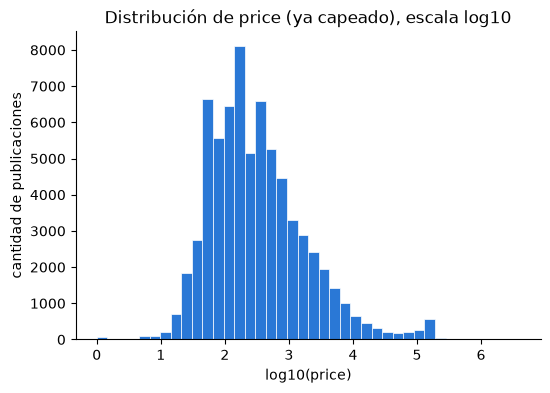

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(np.log10(train["price"]), bins=40, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.set_xlabel("log10(price)")
ax.set_ylabel("cantidad de publicaciones")
ax.set_title("Distribución de price (ya capeado), escala log10")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.show()

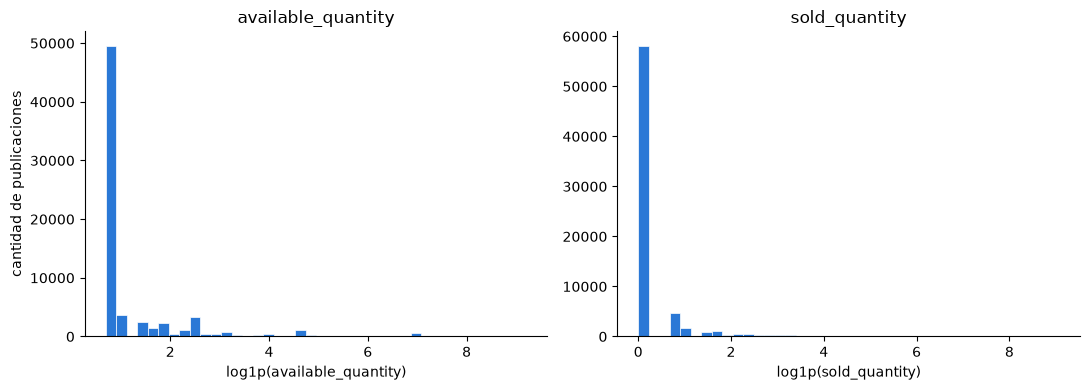

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(np.log1p(train["available_quantity"]), bins=40, color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("log1p(available_quantity)")
axes[0].set_ylabel("cantidad de publicaciones")
axes[0].set_title("available_quantity")

axes[1].hist(np.log1p(train["sold_quantity"]), bins=40, color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[1].set_xlabel("log1p(sold_quantity)")
axes[1].set_title("sold_quantity")

for ax in axes:
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

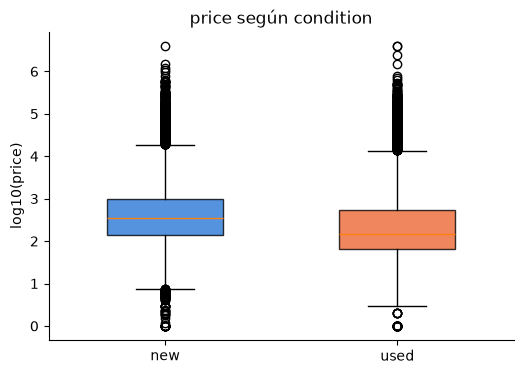

condition
new     350.0
used    150.0
Name: price, dtype: float64

In [15]:
colores_condition = {"new": "#2a78d6", "used": "#eb6834"}
grupos = [np.log10(train.loc[train["condition"] == cond, "price"]) for cond in ["new", "used"]]

fig, ax = plt.subplots(figsize=(6, 4))
box = ax.boxplot(grupos, tick_labels=["new", "used"], patch_artist=True, widths=0.5)
for patch, cond in zip(box["boxes"], ["new", "used"]):
    patch.set_facecolor(colores_condition[cond])
    patch.set_alpha(0.8)
ax.set_ylabel("log10(price)")
ax.set_title("price según condition")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.show()

train.groupby("condition")["price"].median()

# Inciso 4: Categóricas vs `condition`, `category_id`, y redundancia numérica

## 4.1 — Flags y booleanas vs `condition`

Para cada columna booleana, comparo el % de `new` entre las filas `True` y las `False`. Cuanto más grande la diferencia, más "separa" esa variable a `new` de `used`.

In [16]:
columnas_bool = [
    "automatic_relist", "accepts_mercadopago", "free_shipping", "local_pick_up",
    "tiene_descuento", "es_tienda_oficial", "tiene_video", "tiene_garantia",
    "tiene_parent_item", "tiene_sub_status", "tiene_oferta",
] + [f"tag_{t}" for t in tags_posibles]

es_new = train["condition"] == "new"

filas = []
for col in columnas_bool:
    mask = train[col]
    filas.append({
        "columna": col,
        "n_True": mask.sum(),
        "%new_si_True": es_new[mask].mean(),
        "%new_si_False": es_new[~mask].mean(),
    })

resumen_bool = pd.DataFrame(filas).set_index("columna")
resumen_bool["diferencia_abs"] = (resumen_bool["%new_si_True"] - resumen_bool["%new_si_False"]).abs()
resumen_bool.sort_values("diferencia_abs", ascending=False).round(3)

,n_True,%new_si_True,%new_si_False,diferencia_abs
columna,,,,
tag_free_relist,183,0.055,0.538,0.484
tiene_descuento,103,1.000,0.536,0.464
tag_poor_quality_thumbnail,8,1.000,0.537,0.463
tiene_oferta,178,0.989,0.536,0.453
automatic_relist,3312,0.954,0.516,0.438
es_tienda_oficial,575,0.970,0.533,0.437
free_shipping,2117,0.932,0.525,0.407
tag_good_quality_thumbnail,1199,0.894,0.531,0.363
accepts_mercadopago,68468,0.544,0.225,0.319


## 4.2 — Categóricas de varios niveles vs `condition`

Ahora `listing_type_id`, `buying_mode`, `shipping_mode` y `seller_state`. Grafico % de `new` por categoría, con una línea punteada en el promedio general (53.7%) para ver qué categorías se alejan.

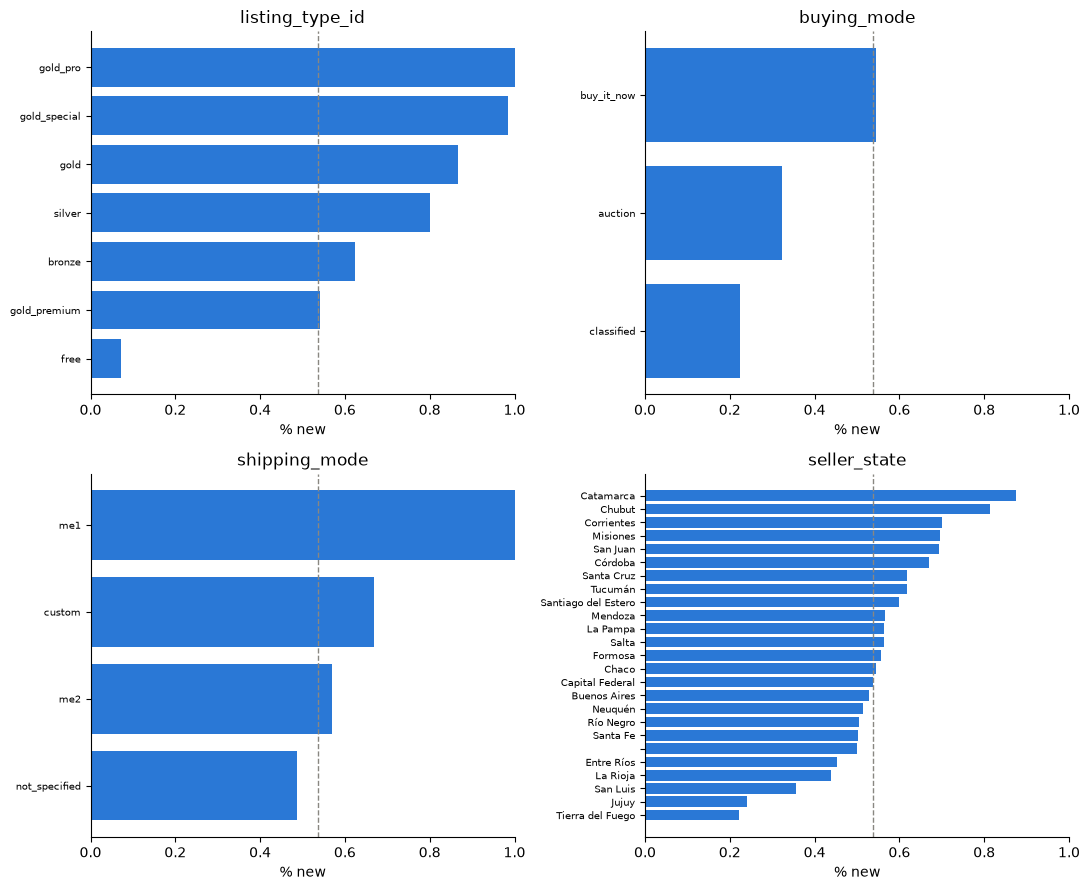

In [17]:
promedio_general = es_new.mean()
columnas_categoricas = ["listing_type_id", "buying_mode", "shipping_mode", "seller_state"]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, col in zip(axes.flat, columnas_categoricas):
    pct_new = train.groupby(col)["condition"].apply(lambda s: (s == "new").mean()).sort_values()
    ax.barh(pct_new.index, pct_new.values, color="#2a78d6")
    ax.axvline(promedio_general, color="#898781", linestyle="--", linewidth=1)
    ax.set_xlabel("% new")
    ax.set_title(col)
    ax.set_xlim(0, 1)
    ax.tick_params(axis="y", labelsize=7)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## 4.3 — `category_id`

Es de alta cardinalidad (como `neighborhood` en el material, `material/Variables Categóricas, Datos Faltantes y Feature Engineering/Tratamiento-de-variables-categóricas.pdf`), así que no la vamos a abrir en dummies (explotaría la cantidad de columnas). Primero mido cuántas categorías hay y qué tan dispersa es la señal (¿el % de `new` varía mucho entre categorías, o es parecido en todas?).

In [18]:
print("Categorías únicas:", train["category_id"].nunique())

resumen_categoria = train.groupby("category_id")["condition"].apply(
    lambda s: pd.Series({"n": len(s), "pct_new": (s == "new").mean()})
).unstack()

soportadas = resumen_categoria[resumen_categoria["n"] >= 100]
print("Categorías con >=100 publicaciones:", len(soportadas))
print("Dispersión de pct_new entre esas categorías:")
print(soportadas["pct_new"].describe())

print("\nMás 'used' (>=100 pubs):")
print(soportadas.sort_values("pct_new").head(5))
print("\nMás 'new' (>=100 pubs):")
print(soportadas.sort_values("pct_new", ascending=False).head(5))

Categorías únicas: 9570


Categorías con >=100 publicaciones: 73
Dispersión de pct_new entre esas categorías:
count    73.000000
mean      0.434166
std       0.330305
min       0.015015
25%       0.144144
50%       0.342105
75%       0.658385
max       1.000000
Name: pct_new, dtype: float64

Más 'used' (>=100 pubs):
                 n   pct_new
category_id                 
MLA15328     333.0  0.015015
MLA41112     135.0  0.037037
MLA2038      468.0  0.064103
MLA1383      315.0  0.076190
MLA41278     103.0  0.077670

Más 'new' (>=100 pubs):
                 n  pct_new
category_id                
MLA373016    122.0      1.0
MLA73721     111.0      1.0
MLA60671     130.0      1.0
MLA60611     216.0      1.0
MLA352345    104.0      1.0


## 4.4 — Redundancia entre numéricas (correlación de Pearson)

Acá sí corresponde correlación de Pearson clásica, porque comparo pares de variables numéricas entre sí (no contra el target categórico). Busco pares muy correlacionados (~1) que serían redundantes para un modelo lineal.

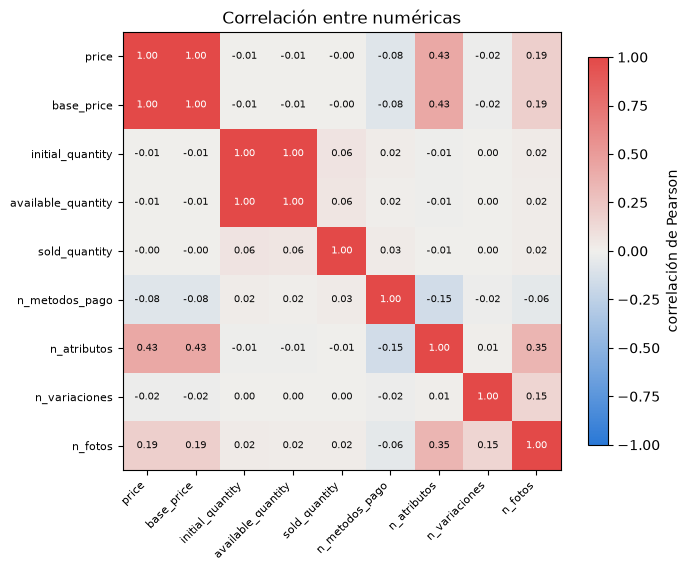

In [19]:
from matplotlib.colors import LinearSegmentedColormap

columnas_numericas_corr = [
    "price", "base_price", "initial_quantity", "available_quantity",
    "sold_quantity", "n_metodos_pago", "n_atributos", "n_variaciones", "n_fotos",
]
corr = train[columnas_numericas_corr].corr()

cmap_diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap=cmap_diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(columnas_numericas_corr)))
ax.set_yticks(range(len(columnas_numericas_corr)))
ax.set_xticklabels(columnas_numericas_corr, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(columnas_numericas_corr, fontsize=8)
for i in range(len(columnas_numericas_corr)):
    for j in range(len(columnas_numericas_corr)):
        valor = corr.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(valor) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8, label="correlación de Pearson")
ax.set_title("Correlación entre numéricas")
plt.tight_layout()
plt.show()

## 4.5 — Chequeo final: columnas que quedaron sin explorar

Antes de cerrar, reviso 4 columnas string que nunca miramos (`status`, `site_id`, `listing_source`, `international_delivery_mode`) — quiero confirmar si son descartables antes de armar la lista final, no asumirlo.

In [20]:
for col in ["status", "site_id", "listing_source", "international_delivery_mode"]:
    print(col, "-> categorías:", train[col].nunique())
    print(train[col].value_counts())
    print()

status -> categorías: 4
status
active            67032
paused             2952
closed               15
not_yet_active        1
Name: count, dtype: int64

site_id -> categorías: 1
site_id
MLA    70000
Name: count, dtype: int64

listing_source -> categorías: 1
listing_source
    70000
Name: count, dtype: int64

international_delivery_mode -> categorías: 1
international_delivery_mode
none    70000
Name: count, dtype: int64



# Conclusión del EDA

## Qué se hizo

1. **Anidadas** (`dict`/`list`): se abrieron en columnas nuevas (`seller_state`, `shipping_mode`, `free_shipping`, `local_pick_up`) o se resumieron en conteos/flags (`n_metodos_pago`, `n_atributos`, `n_variaciones`, `n_fotos`, `tiene_sub_status`, `tiene_oferta`, `tag_*`). `coverage_areas` y `descriptions` se descartaron por no aportar información utilizable.
2. **Nulos**: 8 columnas tenían nulos. 3 (`catalog_product_id`, `differential_pricing`, `subtitle`) eran prácticamente 100% nulas y se eliminaron. Las otras 5 (`original_price`, `official_store_id`, `video_id`, `warranty`, `parent_item_id`) se resumieron en flags de presencia (`tiene_descuento`, `es_tienda_oficial`, `tiene_video`, `tiene_garantia`, `tiene_parent_item`).
3. **Outliers**: `price`/`base_price` tenían 226 filas (0.32%) con errores de carga evidentes (patrones de dígitos repetidos) y dos monedas mezcladas. Se capearon en el percentil 99.5% **por moneda**, calculado solo con train, y se conservó `currency_id` como feature. El resto de las numéricas (cantidades, conteos) no mostró errores, solo asimetría normal de un marketplace.
4. **Distribuciones y relación con `condition`**: `price` separa bien por sí solo (mediana $350 `new` vs $150 `used`). Las variables más discriminativas son señales de "vendedor profesional / tienda oficial" (`tiene_oferta`, `automatic_relist`, `es_tienda_oficial`, `free_shipping`, `accepts_mercadopago`) y el tier de publicación (`listing_type_id`). `category_id` (9.570 categorías) es la señal más fuerte de todas (0%–100% `new` según categoría). `price`≈`base_price` e `initial_quantity`≈`available_quantity` están perfectamente correlacionadas (redundantes).
5. Confirmé que `site_id`, `listing_source` e `international_delivery_mode` son **constantes** (una sola categoría, 70.000 filas) — cero varianza, se descartan.

## Decisión pendiente para `train.ipynb`: transformación de `price`

`price` (ya capeado) sigue siendo muy asimétrico (de $1 a ~$3,98M), y en escala `log10` se ve razonablemente simétrico (visto en el histograma del Inciso 3). **Decisión: aplicar `log(price)` en el Pipeline de `train.ipynb`.**

Justificación: casi todos los modelos del material (regresión logística, LDA/QDA, Naive Bayes gaussiano, kNN, SVM) o bien asumen relación lineal en el log-odds, o son sensibles a la escala/distancia, o asumen features aproximadamente normales — `log(price)` cumple mucho mejor esos supuestos que `price` crudo. Como el mínimo de `price` es $1 (no 0), alcanza con `log` directo, sin necesidad de `log1p`. El capeo (0.32% más extremo) y el log resuelven problemas distintos: uno saca los errores de carga, el otro comprime la asimetría normal del resto de los datos — van juntos, uno no reemplaza al otro.

## Columnas listas para pasar a `train.ipynb`

**Numéricas** (ya capeadas donde correspondía; usar solo una de cada par redundante marcado):
`price` *(redundante con `base_price`, usar una — aplicar `log` en el Pipeline)*, `available_quantity` *(redundante con `initial_quantity`, usar una)*, `sold_quantity`, `n_metodos_pago`, `n_atributos`, `n_variaciones`, `n_fotos`

**Booleanas** (ya en 0/1, listas para usar directo):
`automatic_relist`, `accepts_mercadopago`, `free_shipping`, `local_pick_up`, `tiene_descuento`, `es_tienda_oficial`, `tiene_video`, `tiene_garantia`, `tiene_parent_item`, `tiene_sub_status`, `tiene_oferta`, `tag_dragged_bids_and_visits`, `tag_dragged_visits`, `tag_free_relist`, `tag_good_quality_thumbnail`, `tag_poor_quality_thumbnail`

**Categóricas de pocas clases** (encoding pendiente para `train.ipynb`, ej. One-Hot):
`listing_type_id`, `buying_mode`, `shipping_mode`, `currency_id`, `seller_state`

**Categórica de alta cardinalidad** (Target/Frequency Encoder, no One-Hot):
`category_id`

**Texto** (TF-IDF, como en el baseline de referencia):
`title`

**Target** (solo en train):
`condition`

## Lo que queda afuera (y por qué)

- **Constantes / sin señal**: `site_id`, `listing_source`, `international_delivery_mode`, `coverage_areas`.
- **Crudas ya reemplazadas por su flag/derivada**: `original_price`, `official_store_id`, `video_id`, `parent_item_id`, `seller_address`, `shipping`, `tags`, `non_mercado_pago_payment_methods`, `attributes`, `variations`, `pictures`, `sub_status`, `deal_ids`.
- **Sin texto útil**: `descriptions` (solo trae un id de referencia).
- **Identificadores/metadata no predictiva**: `id`, `seller_id`, `permalink`, `thumbnail`, `secure_thumbnail`.
- **Pendientes de explorar** (no alcanzamos en este EDA, quedan para una vuelta futura si hace falta): `date_created`, `start_time`, `stop_time`, `last_updated` (posibles features de tiempo), `status` (4 categorías, 95.8% `active` — señal probablemente chica), `warranty` como texto (más allá del flag `tiene_garantia`).